[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/Jordy-Castillo/FC_Jordy-Castillo-Trabajos/blob/main/Taller05/FC_Taller05_JordyCastillo.ipynb)

# **FISICA COMPUTACIONAL - TALLER #5**
* **Tema:** Metodo de Monte Carlo en FORTRAN
* **Lenguaje:** Fortran
* **Estudiante:** Jordy Castillo Jordán
* **Fecha:** 22/10/2026



In [51]:
!which gfortran || (apt-get update -qq && apt-get install -y gfortran)
!gfortran --version | head -n 1

/usr/bin/gfortran
GNU Fortran (Ubuntu 13.3.0-6ubuntu2~24.04.1) 13.3.0


# **PARTE A:**

Para cada $N = 10^2, 10^3, \ldots, 10^7$, repita el cálculo de $\hat\pi$ de la sección 2 con $M = 20$ semillas distintas. Si las estimaciones son $\hat\pi_1, \ldots, \hat\pi_M$, su media y su desviación estándar muestral son
$$\bar\pi = \frac1M\sum_{j=1}^M \hat\pi_j, \qquad
s = \sqrt{\frac{M}{M-1}\left(\frac1M\sum_{j=1}^M \hat\pi_j^2 - \bar\pi^2\right)}.$$
Distinga $s$, que describe una corrida típica, de $s/\sqrt M$, que describe la incertidumbre de la media de las $M$ corridas. La sección 3 predice $s \approx 1.642/\sqrt{N}$.

Si el error decrece como $1/\sqrt{N}$, los puntos $(\log_{10} N, \log_{10} s)$ caen sobre una recta de pendiente $-1/2$. La pendiente de $n$ puntos $(X_k, Y_k)$ por mínimos cuadrados (Semana 3) es
$$m = \frac{n\sum X_k Y_k - \sum X_k \sum Y_k}{n\sum X_k^2 - \left(\sum X_k\right)^2}.$$

Complete los **cinco bloques TODO** de `taller5_pi.f90`. El programa guarda en `convergencia.dat` el valor de $N$, la media y la desviación, y en `pendiente.dat` la pendiente $m$. El caso $N = 10^7$ tarda unos segundos. Al depurar puede reducir temporalmente el límite superior del ciclo en `k`; restáurelo a 7 antes de entregar.

<div style="background-color:#eef7ee; border-left:5px solid #4caf50; padding:10px 15px; margin:10px 0;"><b>Prueba manual:</b> con $N = 100$ cada estimación de $\pi$ debe estar entre 0 y 4, y la desviación de las 20 corridas debería ser del orden de $0.16$. Con $N = 10^7$, la media debería coincidir con $\pi$ en al menos tres decimales.</div>

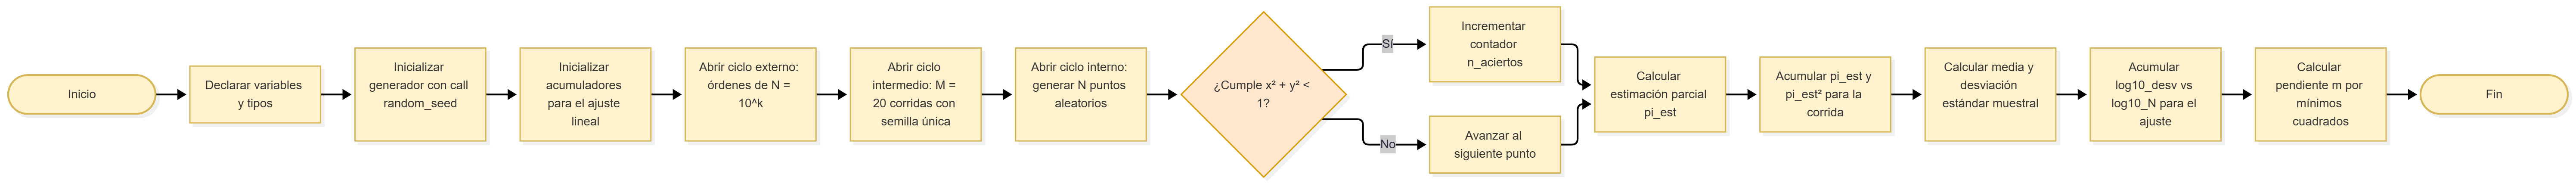

In [ ]:
#ELABORACION MEDIANTE MERMAID
from IPython.display import Image
Image(filename="/content/T5_DiagramaA.png")

In [53]:
%%writefile taller5_pi.f90
! Taller 5 -- Convergencia del estimador de pi por acierto y error.
! Salidas: convergencia.dat (N, media, desviación) y pendiente.dat (pendiente m).

!-----------------------------------------------------------------------------------------------!

program taller5_pi
  implicit none
  integer, parameter :: dp = kind(1.0d0)                       !precisión de punto flotante
  integer, parameter :: M = 20                                 !corridas por cada N
  integer :: k, j, n_sem, u_dat, n_puntos                      !contadores
  integer(8) :: i, n_total, n_aciertos                         !contadores
  integer, allocatable :: semilla(:)                           !semillas de random_seed
  real(dp) :: u, v, x, y, pi_est, suma, suma2, media, desv     !variables generadas
  real(dp) :: X_k, Y_k, sx, sy, sxx, sxy, pendiente            !variables minimos cuadrado

!-----------------------------------------------------------------------------------------------!

  call random_seed(size=n_sem)                                              !configurar generador
  allocate(semilla(n_sem))                                                  !reservar una "memoria" para las semillas

  sx = 0.0_dp; sy = 0.0_dp; sxx = 0.0_dp; sxy = 0.0_dp; n_puntos = 0        !sumas del ajuste
  open(newunit=u_dat,file='convergencia.dat',status='replace')

!-----------------------------------------------------------------------------------------------!

  do k = 2, 7                                                  !N = 10^2, ..., 10^7 (crear ciclo)
     n_total = 10_8**k                                         !10_8 asegura que sea entero
     suma = 0.0_dp; suma2 = 0.0_dp                             !sumas sobre las M corridas (reiniciando)
     do j = 1, M
        semilla = 1000*k + j                                   !una semilla distinta por corrida
        call random_seed(put=semilla)

!-----------------------------------------------------------------------------------------------!
! TODO A1: obtenga pi_est con n_total puntos uniformes en el cuadrado (sección 2)

        n_aciertos = 0_8                                         !acumulador
        do i = 1_8, n_total
          call random_number(u)                                  !u en [0,1)
          call random_number(v)                                  !v en [0,1)
          x = 2.0_dp*u - 1.0_dp                                  !cambio de intervalo a [-1,1]
          y = 2.0_dp*v - 1.0_dp                                  !cambio de intervalo a [-1,1]
          if (x*x + y*y < 1.0_dp) then
            n_aciertos = n_aciertos + 1_8                        !este es el punto dentro del circulo
          end if
        end do

        pi_est = 4.0_dp* real(n_aciertos, dp) / real(n_total, dp)   !estimacion de pi
        !al convertir n_aciertos y n_total a real(dp), se evita la division entera

!-----------------------------------------------------------------------------------------------!
! TODO A2: acumule lo necesario para la media y la desviación de las M corridas.

        suma = suma + pi_est                        !acumular pi_est
        suma2 = suma2 + pi_est*pi_est               !acumular pi_est^2
     end do

!-----------------------------------------------------------------------------------------------!
! TODO A3: calcule la media y la desviación estándar muestral de las M estimaciones.

     media = suma/real(M,dp)                                                                  !calculamos la media
     desv = sqrt((real(M, dp) / (real(M, dp) - 1.0_dp)) * (suma2 / real(M, dp) - media**2))   !se usa la ecuacion del enunciado

     write(u_dat,'(i10,2es25.16e3)') n_total,media,desv          !guardar archivos
     print '(i10,2f12.6)', n_total,media,desv                    !imprimir en pantalla

!-----------------------------------------------------------------------------------------------!
! TODO A4: acumule lo necesario para ajustar log10(desv) contra log10(N).

     X_k = log10(real(n_total,dp))
     Y_k = log10(desv)
     sx = sx + X_k
     sy = sy + Y_k
     sxx = sxx + X_k*X_k
     sxy = sxy + X_k*Y_k
     n_puntos = n_puntos + 1

  end do
  close(u_dat)

!-----------------------------------------------------------------------------------------------!
 ! TODO A5: calcule la pendiente del ajuste por mínimos cuadrados.

  pendiente = (real(n_puntos, dp)*sxy - sx*sy)/(real(n_puntos, dp)*sxx - sx*sx)   !ajuste por minimos cuadrados

  open(newunit=u_dat,file='pendiente.dat',status='replace')                       !escribimos pendiente en archivo
  write(u_dat,'(es25.16e3)') pendiente
  close(u_dat)

  print '(a,f9.4)', 'Pendiente de log10(s) contra log10(N): ', pendiente          !imprimimos
end program taller5_pi

Overwriting taller5_pi.f90


In [54]:
!rm -f convergencia.dat pendiente.dat
!gfortran -std=f2008 -O2 -fcheck=all -o taller5_pi taller5_pi.f90 && ./taller5_pi

       100    3.134000    0.161714
      1000    3.126600    0.049779
     10000    3.137260    0.015822
    100000    3.142696    0.003486
   1000000    3.141116    0.002166
  10000000    3.141530    0.000400
Pendiente de log10(s) contra log10(N):   -0.5079


**Visualización:** La gráfica usa exclusivamente `convergencia.dat` producido por FORTRAN. Compare la desviación medida con la predicción $1.642/\sqrt{N}$.

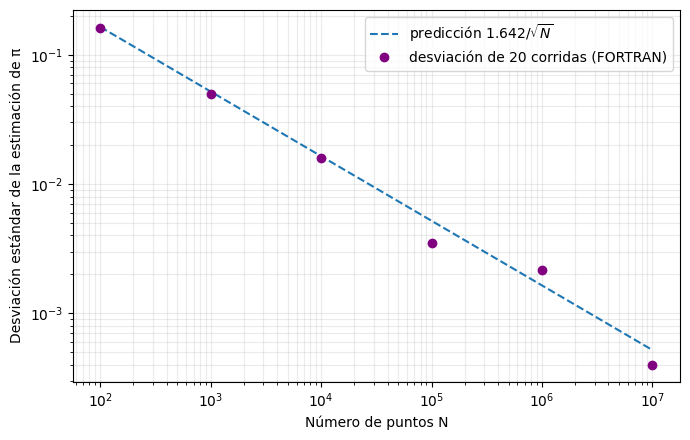

In [55]:
import numpy as np
import matplotlib.pyplot as plt

# Lee N, media y desviación calculadas por el programa FORTRAN.
N, media, desv = np.loadtxt('convergencia.dat', ndmin=2).T

plt.figure(figsize=(7,4.5))
plt.loglog(N, 1.642/np.sqrt(N), '--', label=r'predicción $1.642/\sqrt{N}$')
if np.any(desv > 0):
    plt.loglog(N[desv > 0], desv[desv > 0], 'o', color="purple", label='desviación de 20 corridas (FORTRAN)')
plt.xlabel('Número de puntos N')
plt.ylabel('Desviación estándar de la estimación de π')
plt.grid(True, which='both', alpha=.25)
plt.legend()
plt.tight_layout()
plt.savefig('convergencia_pi.png', dpi=180)
plt.show()



---


# **PARTE B:**

En el método de **valor medio**, tome $x=a+(b-a)u$ con $u$ uniforme en $[0,1)$ y estime
$$I_\mathrm{VM}=\frac{b-a}{N}\sum_{i=1}^{N}\sin x_i.$$

En **acierto y error**, construya puntos $(x,y)$ uniformes en el rectángulo $[0,\pi/2)\times[0,1)$, cuente los puntos que cumplen $y<\sin x$ y estime
$$I_\mathrm{AE}=(b-a)\frac{N_\mathrm{bajo}}{N}.$$

Para comparar los métodos, repita cada cálculo $R$ veces y obtenga la media y la desviación estándar muestral de las $R$ estimaciones, con las mismas fórmulas de la Parte A.

Complete los **cuatro bloques TODO** de `taller5_seno.f90`. Cada repetición calcula las dos integrales con $N=1000$ puntos; se realizan $R=1000$ repeticiones para medir la dispersión de los estimadores. El programa guarda en `seno.dat` la media y la desviación estándar muestral de cada método. Compare las medias con 1 y las dispersiones con $0.483/\sqrt{N}$ (valor medio) y $0.756/\sqrt{N}$ (acierto y error). Al depurar puede disminuir temporalmente `R`; restáurelo a 1000 antes de entregar.

<div style="background-color:#eef7ee; border-left:5px solid #4caf50; padding:10px 15px; margin:10px 0;"><b>Prueba manual:</b> En una repetición completa, cada integral debe estar entre 0 y π/2. Al terminar, las dos medias deberían ser próximas a 1. Las desviaciones entre corridas deben ser positivas y no serán iguales para los dos métodos.</div>

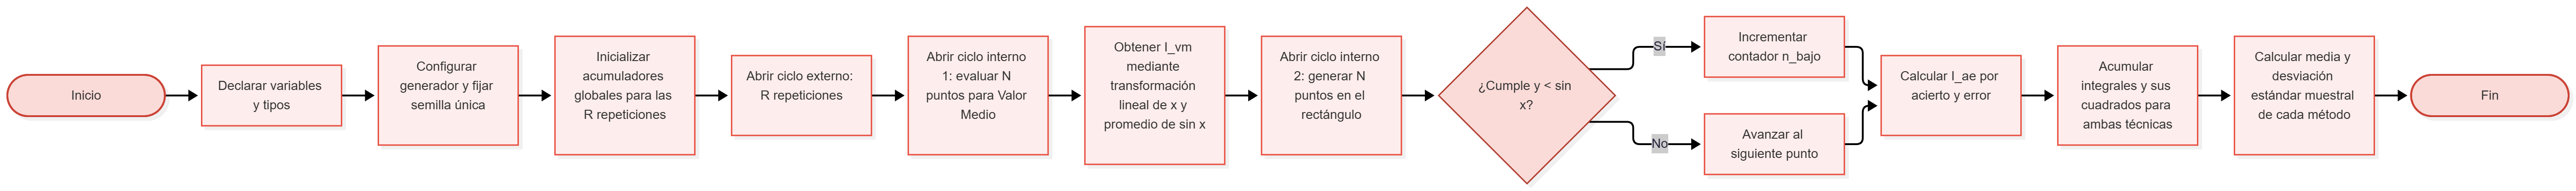

In [ ]:
#ELABORACION MEDIANTE MERMAID
from IPython.display import Image
Image(filename="/content/T5_DiagramaB.png")

In [59]:
%%writefile taller5_seno.f90
! Taller 5 -- Integral de sin(x) en [0,pi/2) por valor medio y acierto y error.
! Salida: seno.dat (media_vm, desv_vm, media_ae, desv_ae).

!-----------------------------------------------------------------------------------------------!

program taller5_seno
  implicit none
  integer, parameter :: dp = kind(1.0d0)                                           !precisión de punto flotante
  integer, parameter :: N = 1000, R = 1000                                         !muestras por corrida y repeticiones
  real(dp), parameter :: a = 0.0_dp, b = 2.0_dp*atan(1.0_dp), H = 1.0_dp           !rangos de integración
  integer :: rep, i, n_bajo, n_sem, u_dat                                          !contadores a usar
  integer, allocatable :: semilla(:)                                               !semillas random
  real(dp) :: u, v, x, y, suma_f, I_vm, I_ae                                       !variables
  real(dp) :: s_vm, s2_vm, s_ae, s2_ae, media_vm, desv_vm, media_ae, desv_ae       !variables

!-----------------------------------------------------------------------------------------------!

!El tamaño del arreglo de semilla depende de la implementación.
  call random_seed(size=n_sem)                                         !configurar generador
  allocate(semilla(n_sem))                                             !conservar una "memoria" para las semillas
  semilla = 314                                                        !se elige una semilla fija
  call random_seed(put=semilla)                                        !se fija una vez, antes de las R corridas

  !acumuladores para las R corridas
  s_vm = 0.0_dp
  s2_vm = 0.0_dp
  s_ae = 0.0_dp
  s2_ae = 0.0_dp


!-----------------------------------------------------------------------------------------------!
! TODO B1: obtenga I_vm por valor medio usando N puntos (sección 4).

  do rep = 1, R
     suma_f = 0.0_dp                                                    !creamos un contado de la suma
     do i = 1, N                                                        !creamos ciclo para N
       call random_number(u)                                            !u en [0,1)
       x = a + (b-a)*u                                                  !realizamos la combinacion lineal para [0, pi/2)
       suma_f = suma_f + sin(x)                                         !acumulamos la suma
     end do
     I_vm = (b-a)*(suma_f/real(N,dp))                                   !calculamos integral con la ecuacion

!-----------------------------------------------------------------------------------------------!
! TODO B2: obtenga I_ae por acierto y error en [a,b) x [0,H) (sección 4).

     n_bajo= 0                                                          !contador de puntos debajo de la curva
     do i = 1,N
       call random_number(u)
       call random_number(v)
       x = a + (b-a)*u                                                  !combinacion lineal para x para [0, pi/2)
       y = v*H                                                          !combinacion lineal para y para [0,1)
       if (y < sin(x)) then                                             !los puntos deben cumplir esta condicion
         n_bajo = n_bajo + 1                                            !punto debajo de la curva de sin(x)
       end if
     end do

     I_ae = (b-a)*H*((real(n_bajo,dp))/real(N,dp))                      !calculamos integral con la ecuacion

!-----------------------------------------------------------------------------------------------!
! TODO B3: acumule las dos integrales y sus cuadrados para las R corridas.

     s_vm = s_vm + I_vm                                                 !sumatoria para ajuste
     s2_vm = s2_vm + I_vm*I_vm
     s_ae = s_ae + I_ae
     s2_ae = s2_ae + I_ae*I_ae

  end do

!-----------------------------------------------------------------------------------------------!
! TODO B4: calcule media y desviación estándar muestral para cada método.

  media_vm = s_vm/real(R,dp)
  desv_vm = sqrt((real(R, dp) / (real(R, dp) - 1.0_dp)) * (s2_vm / real(R, dp) - media_vm**2))

  media_ae = s_ae/real(R,dp)
  desv_ae = sqrt((real(R, dp) / (real(R, dp) - 1.0_dp)) * (s2_ae / real(R, dp) - media_ae**2))

  !Cuatro números sin encabezado para la lectura automática (guardar archivo)
  open(newunit=u_dat,file='seno.dat',status='replace')
  write(u_dat,'(4es25.16e3)') media_vm,desv_vm,media_ae,desv_ae
  close(u_dat)

  !imprimos los resultados
  print '(a,2f10.5)', 'Valor medio (media, desviacion): ',media_vm,desv_vm
  print '(a,2f10.5)', 'Acierto y error (media, desviacion): ',media_ae,desv_ae

end program taller5_seno

Overwriting taller5_seno.f90


In [60]:
!rm -f seno.dat
!gfortran -std=f2008 -O2 -fcheck=all -o taller5_seno taller5_seno.f90 && ./taller5_seno

Valor medio (media, desviacion):    0.99973   0.01529
Acierto y error (media, desviacion):    1.00009   0.02465




---


# **PARTE C:**
Repita el cálculo de $\hat\pi$ de la sección 2 para $N = 10^2, \ldots, 10^7$, con una sola corrida por cada $N$, pero tome las coordenadas $(x, y)$ de números consecutivos del LCG $(57, 1, 256)$ de la sección 5, con semilla $r = 10$, en lugar de `random_number`.

Complete el **bloque TODO** de `taller5_lcg.f90`. El programa guarda en `lcg.dat` el valor de $N$ y la estimación $\hat\pi$. Compare cómo cambia el error con $N$ frente a lo observado en la Parte A.

<div style="background-color:#fdecea; border-left:5px solid #e53935; padding:10px 15px; margin:10px 0;"><b>Interprete el error con cuidado:</b> La desviación $s$ estima la escala típica de fluctuación, no un límite que cada corrida deba respetar. Por eso la Parte A mide $s$ con 20 corridas en lugar de usar una sola. En la Parte C, en cambio, el error no es una fluctuación: es sistemático.</div>

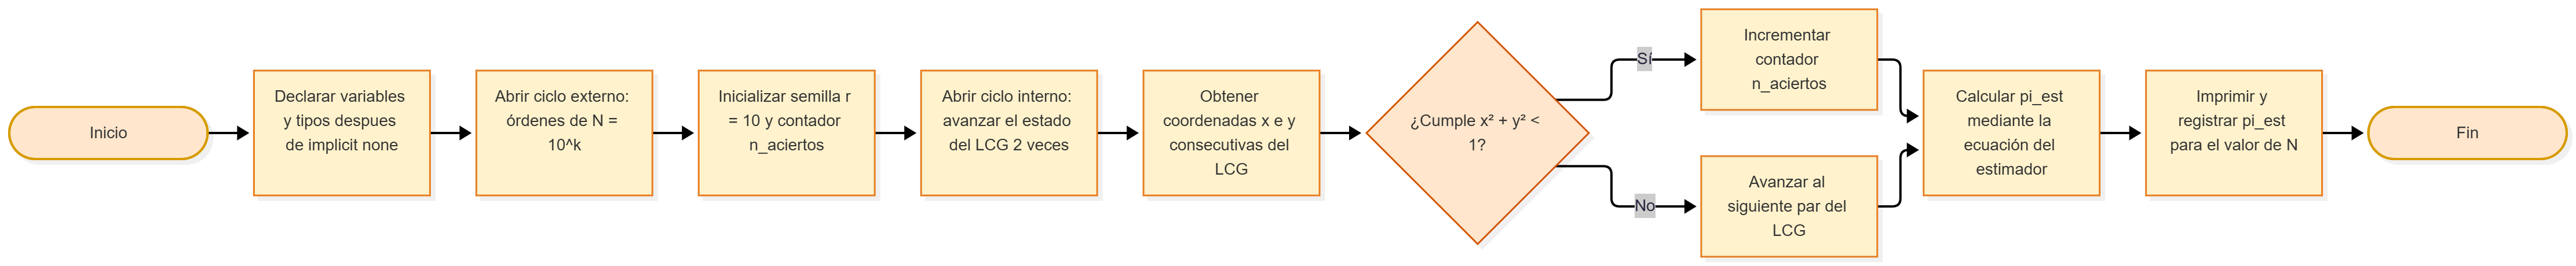

In [ ]:
#ELABORACION MEDIANTE MERMAID
from IPython.display import Image
Image(filename="/content/T5_DiagramaC.png")

In [62]:
%%writefile taller5_lcg.f90
! Taller 5 -- pi por acierto y error con el LCG (57, 1, 256) en lugar de random_number.
! Salida: lcg.dat (N, pi_est).

!-----------------------------------------------------------------------------------------------!

program taller5_lcg
  implicit none
  integer, parameter :: dp = kind(1.0d0)
  integer, parameter :: a_lcg = 57, c_lcg = 1, M_lcg = 256
  integer :: k, r, u_dat
  integer(8) :: i, n_total, n_aciertos
  real(dp) :: x, y, pi_est

!-----------------------------------------------------------------------------------------------!

  open(newunit=u_dat,file='lcg.dat',status='replace')
  do k = 2, 7                                   ! N = 10^2, ..., 10^7
     n_total = 10_8**k                          ! limites de puntos
     r = 10                                     ! semilla del LCG, la misma para cada N
     n_aciertos = 0_8                           ! contar de puntos dentro del circulo

!-----------------------------------------------------------------------------------------------!
! TODO C1: obtenga pi_est con n_total puntos cuyas coordenadas salen del LCG (sección 5).
     do i= 1_8, n_total                                 !crear ciclo para N
       r= mod(a_lcg*r + c_lcg, M_lcg)                   !avanzar el estado del LCG
       x = 2.0_dp*real(r,dp) / M_lcg - 1.0_dp
       r= mod(a_lcg*r + c_lcg, M_lcg)                   !avanzar el estado del LCG otra vez
       y = 2.0_dp*real(r,dp) / M_lcg - 1.0_dp

       if (x*x + y*y < 1.0_dp) then                     !verificar si pertenece al circulo de radio 1
         n_aciertos = n_aciertos + 1_8
       end if
     end do

     pi_est = 4.0_dp* real(n_aciertos, dp) / real(n_total, dp)    !calcular pi con la formula despejada de la presentacion

     write(u_dat,'(i10,es25.16e3)') n_total,pi_est
     print '(i10,f12.6)', n_total,pi_est
  end do
  close(u_dat)

end program taller5_lcg

Overwriting taller5_lcg.f90


In [63]:
!rm -f lcg.dat
!gfortran -std=f2008 -O2 -fcheck=all -o taller5_lcg taller5_lcg.f90 && ./taller5_lcg

       100    3.040000
      1000    3.084000
     10000    3.093200
    100000    3.093720
   1000000    3.093740
  10000000    3.093750




---


# **PARTE D:**


**1. Con la pendiente de la Parte A, ¿cuántos puntos se necesitarían para obtener $\pi$ con un error de $10^{-6}$? ¿Es práctico?**

Segun la teoria, se puede calcular la cantidad de puntos ($N$) al despejarla de la siguiente expresion, teniendo en cuenta que la pendiente hallada fue de $m=-0.5079$, y que $(ϵ)$ es el error/precision, es decir que se confirma la relacion presentada al coincidir con la pendiente esperada.

$$ϵ=\frac{1.642}{\sqrt{N}} --> 10^{-6} =\frac{1.642}{\sqrt{N}} --> N=(\frac{1.642}{10^{-6}})^{2} --> N= 2.7 \times 10^{12}  $$

La cantidad de puntos necesarios esta en la escala de billones, siendo de orden $10^{12}$, lo cual es un numero bastante grande. Dicha cifra podria durar muchas horas o incluso dias en ser preocesados por una computadora, unicamente para ganar unas cifras de precisión, por ende, no es muy practico. Esto apoya la premisa de que esta version del metodo de Monte Carlo no es muy eficaz.

\
\
**2. Con el mismo $N$, ¿cuál método de la Parte B tiene menor dispersión? ¿Por qué? ¿Bastaría una sola corrida para afirmarlo?**

El metodo de Valor Medio posee una menor dispersion $0.01529$ en comparacion a $0.2465$ del Acierto y Error, segun la parte B calculada. Esto se espera debido a que el Valor Medio usa el valor continuo de $\sin(x)$, por otro lado, el de Acierto y Error transforma la informacion al catalogar los puntos en 0 o 1, perdiendo informacion de la funcion planteada.

Ademas, con una sola ejecucion, los resultados cambian al azar. Es por ello que se realizarn multiples repeticiones, con el fin de comparar las desviaciones estandar muestrales.


\
\
**3. ¿Por qué, con el LCG de la Parte C, aumentar $N$ no reduce el error, aunque cada número esté en $[0,1)$?**

Hay que tener en cuenta que un LCG genera numeros limitados por [0,1), ademas de que posee un periodo muy pequeño (256 estados). Al tomar los numeros de dos en dos, solo pueden formarse aproximadamente 128 puntos diferentes ($256/2 = 128$). Y como el metodo de Monte Carlo asume que cada muestra es una variable aleatoria *independiente* y distribuida correctamente, hace que dicha premisa se rompa, ya que se repiten los mismos 128 puntos una y otra vez en un bucle (cuando tomamos N mayores a 128). Por ende, la estimacion de (π) se detiene aproximadamente en $3.09375$.


\
\
**4. ¿Por qué el cálculo de $\pi$ es una integral en 2D, aunque su estimador se escriba como una fracción?**

El cálculo de $\pi$ mediante el método de Acierto y Error es el cálculo de una integral doble (2D), sobre el dominio plano $\Omega = [-1,1] \times [-1,1]$. Es decir, que se busca evaluar el área del círculo unitario expresándola como la integral de $\theta(x, y)$, el cual toma el valor de $1$ si la condición $x^2 + y^2 < 1$ se satisface y $0$ en caso contrario:

$Area = \int_{-1}^{1}   \theta(x,y) \, dx \, dy$

Aunque el estimador se exprese como una simple fracción de recuento $4 \, (N_{\text{dentro}} / N)$, dicha relación representa la aproximación discreta de Monte Carlo para el valor esperado de $\theta(x, y)$ promediado sobre $N$ muestras aleatorias evaluadas en el plano. Es por ello que, el calculo es bidimensional, ya que depende del muestreo en el espacio cartesiano $(x, y)$.




---


##**Verificación final PASS/FAIL**

Ejecute esta celda **después** de volver a guardar, compilar y correr los tres programas del taller. Comprueba que los archivos fueron producidos por los `.f90` actuales y compara los resultados con valores de referencia, permitiendo fluctuaciones estadísticas. Antes de resolver los TODO la celda debe mostrar FAIL, sin detener el notebook. Un PASS no sustituye la revisión de su código ni de sus explicaciones.

In [64]:
from pathlib import Path
import numpy as np

veredictos = []
def informar(nombre, condicion, detalle=''):
    estado = 'PASS' if condicion else 'FAIL'
    veredictos.append(bool(condicion))
    print(f'{estado} | {nombre}' + (f' — {detalle}' if detalle else ''))

def leer_salida(archivo, fuente, columnas):
    ruta, programa = Path(archivo), Path(fuente)
    if not programa.exists() or not ruta.exists():
        raise ValueError(f'Falta {archivo} o {fuente}; ejecute ambas celdas del programa.')
    if ruta.stat().st_mtime < programa.stat().st_mtime:
        raise ValueError(f'{archivo} es anterior a {fuente}; compile y ejecute otra vez.')
    datos = np.loadtxt(ruta, ndmin=2)
    if datos.shape[1] != columnas or not np.isfinite(datos).all():
        raise ValueError(f'Formato o valores incorrectos en {archivo}.')
    return datos

niveles = 10.0**np.arange(2, 8)                # N = 10^2, ..., 10^7

# --- Parte A: media y dispersión de 20 corridas; pendiente calculada en FORTRAN ---
try:
    filas = leer_salida('convergencia.dat','taller5_pi.f90',3)
    if filas.shape != (6,3) or not np.allclose(filas[:,0], niveles):
        raise ValueError('Se requieren seis filas con N=10^2,...,10^7.')
    n, media, desv = filas.T
    sigma = 1.642/np.sqrt(n)
    ok = (abs(media[4]-np.pi) < 6*sigma[4]/np.sqrt(20)
          and np.all((.45*sigma < desv) & (desv < 1.6*sigma)))
    informar('Convergencia de pi', ok,
             f'media(N=10^6)={media[4]:.6f}, s(N=10^6)={desv[4]:.6f}, predicción={sigma[4]:.6f}')
except Exception as error:
    informar('Convergencia de pi',False,str(error))

try:
    n, media, desv = leer_salida('convergencia.dat','taller5_pi.f90',3).T
    m = leer_salida('pendiente.dat','taller5_pi.f90',1)[0,0]
    if len(n) != 6 or not np.all(desv > 0):
        raise ValueError('convergencia.dat debe tener seis desviaciones positivas.')
    m_datos = np.polyfit(np.log10(n), np.log10(desv), 1)[0]
    informar('Pendiente del ajuste en FORTRAN', -.6 < m < -.4 and abs(m-m_datos) < 1e-4,
             f'm={m:.4f}, predicción=-0.5')
except Exception as error:
    informar('Pendiente del ajuste en FORTRAN',False,str(error))

# --- Parte B: integral de sin x por dos métodos ---
try:
    filas = leer_salida('seno.dat','taller5_seno.f90',4)
    if filas.shape != (1,4):
        raise ValueError('seno.dat debe contener media y desviación de cada método.')
    vm, svm, ae, sae = filas[0]
    n, repeticiones = 1000,1000
    sigma_vm = np.sqrt(np.pi**2/8-1)/np.sqrt(n)
    sigma_ae = np.sqrt(np.pi/2-1)/np.sqrt(n)
    ok_vm = (abs(vm-1)<6*sigma_vm/np.sqrt(repeticiones)
             and .65*sigma_vm < svm < 1.35*sigma_vm)
    ok_ae = (abs(ae-1)<6*sigma_ae/np.sqrt(repeticiones)
             and .65*sigma_ae < sae < 1.35*sigma_ae)
    informar('Integral 1D, valor medio',ok_vm,
             f'media={vm:.6f}, dispersión={svm:.6f}')
    informar('Integral 1D, acierto y error',ok_ae,
             f'media={ae:.6f}, dispersión={sae:.6f}')
except Exception as error:
    informar('Integral 1D, valor medio',False,str(error))
    informar('Integral 1D, acierto y error',False,'Revise el mismo programa.')

# --- Parte C: con el LCG la estimación se estanca lejos de pi ---
try:
    filas = leer_salida('lcg.dat','taller5_lcg.f90',2)
    if filas.shape != (6,2) or not np.allclose(filas[:,0], niveles):
        raise ValueError('Se requieren seis filas con N=10^2,...,10^7.')
    pi_lcg = filas[:,1]
    error_lcg = abs(pi_lcg - np.pi)
    ok = .02 < error_lcg[-1] < .2 and abs(pi_lcg[-1]-pi_lcg[-3]) < 1e-3
    informar('Generador deficiente', ok,
             f'|error| con N=10^5: {error_lcg[-3]:.4f}; con N=10^7: {error_lcg[-1]:.4f}')
except Exception as error:
    informar('Generador deficiente',False,str(error))

print(f'\nRESUMEN: {sum(veredictos)}/{len(veredictos)} PASS')
print('Las explicaciones científicas, los comentarios del código y el informe se revisan aparte.')

PASS | Convergencia de pi — media(N=10^6)=3.141116, s(N=10^6)=0.002166, predicción=0.001642
PASS | Pendiente del ajuste en FORTRAN — m=-0.5079, predicción=-0.5
PASS | Integral 1D, valor medio — media=0.999731, dispersión=0.015292
PASS | Integral 1D, acierto y error — media=1.000085, dispersión=0.024645
PASS | Generador deficiente — |error| con N=10^5: 0.0479; con N=10^7: 0.0478

RESUMEN: 5/5 PASS
Las explicaciones científicas, los comentarios del código y el informe se revisan aparte.




---


### **CALCULO DE ERP**
A continuación, realizaremos los cálculos automáticos de los ERPs para cada sección del taller con la formula;

$$\text{ERP}(\%) = \left| \frac{\text{Valor Calculado} - \text{Valor de Referencia}}{\text{Valor de Referencia}} \right| \times 100$$



#### PARTE A

* Referencia de la Pendiente: $-0.5$
* Referencia de la Media: $\pi \approx 3.141592653589793$
* Referencia de la Desviación ($s$): $1.642 / \sqrt{N}$

In [67]:
#Cargar los datos de los archivos
datos = np.loadtxt('convergencia.dat')
N_vals = datos[:, 0]
medias = datos[:, 1]
desvs = datos[:, 2]

pendiente_calc = np.loadtxt('pendiente.dat')

#Calcular el ERP de la Pendiente
pendiente_ref = -0.5
erp_pendiente = abs(pendiente_calc - pendiente_ref) / abs(pendiente_ref) * 100

print("--- RESULTADO DE LA PENDIENTE ---")
print("Pendiente Calculada:", pendiente_calc)
print("ERP Pendiente:", round(erp_pendiente, 3), "%\n")

print("--- RESULTADOS PARA CADA N ---")

#Ciclo for para contar los diferentes N
for i in range(len(N_vals)):
    N = N_vals[i]
    media_actual = medias[i]
    desv_actual = desvs[i]

    #Valor de referencia teórico con numpy
    ref_media = np.pi

    #Cálculo del ERP para la media
    erp_media = abs(media_actual - ref_media) / ref_media * 100

    #imprimimos los resultados con sus cifras significativas de acorde a las partes anteriores
    print(f"Para N = {int(N)}:")
    print(f"  - Media Calculada: {media_actual:.6f}")
    print(f"  - ERP Media: {erp_media:.3f}%")
    print("-" * 30) #añadir una linea (aprendido de internet)

--- RESULTADO DE LA PENDIENTE ---
Pendiente Calculada: -0.507926196588057
ERP Pendiente: 1.585 %

--- RESULTADOS PARA CADA N ---
Para N = 100:
  - Media Calculada: 3.134000
  - ERP Media: 0.242%
------------------------------
Para N = 1000:
  - Media Calculada: 3.126600
  - ERP Media: 0.477%
------------------------------
Para N = 10000:
  - Media Calculada: 3.137260
  - ERP Media: 0.138%
------------------------------
Para N = 100000:
  - Media Calculada: 3.142696
  - ERP Media: 0.035%
------------------------------
Para N = 1000000:
  - Media Calculada: 3.141116
  - ERP Media: 0.015%
------------------------------
Para N = 10000000:
  - Media Calculada: 3.141530
  - ERP Media: 0.002%
------------------------------


#### PARTE B

 **Valor Medio (VM):**
  * Media de referencia: $1.0$
  * Desviación de referencia ($s_{vm}$): $0.483 / \sqrt{1000}$

 **Acierto y Error (AE):**
  * Media de referencia: $1.0$
  * Desviación de referencia ($s_{ae}$): $\sqrt{\pi/2 - 1} / \sqrt{1000}$

In [68]:
#Cargar los datos de 'seno.dat'
datos = np.loadtxt('seno.dat')
media_vm = datos[0]
desv_vm = datos[1]
media_ae = datos[2]
desv_ae = datos[3]

#contador de N
N_b = 1000

#Valores de referencia teóricos
ref_media_b = 1.0
ref_desv_vm = 0.483 / np.sqrt(N_b)
ref_desv_ae = np.sqrt(np.pi / 2.0 - 1.0) / np.sqrt(N_b)

#Cálculos de ERP
erp_m_vm = abs(media_vm - ref_media_b) / ref_media_b * 100
erp_d_vm = abs(desv_vm - ref_desv_vm) / ref_desv_vm * 100

erp_m_ae = abs(media_ae - ref_media_b) / ref_media_b * 100
erp_d_ae = abs(desv_ae - ref_desv_ae) / ref_desv_ae * 100

#Imprimimos los resultados
print("--- MÉTODO: VALOR MEDIO (VM) ---")
print(f"  - Media Calculada: {media_vm:.5f}")
print(f"  - ERP Media: {erp_m_vm:.3f}%")
print(f"  - Desviación Calculada: {desv_vm:.5f}")
print(f"  - Desviación Referencia: {ref_desv_vm:.5f}")
print(f"  - ERP Desviación: {erp_d_vm:.3f}%")
print("-" * 35)

print("--- MÉTODO: ACIERTO Y ERROR (AE) ---")
print(f"  - Media Calculada: {media_ae:.5f}")
print(f"  - ERP Media: {erp_m_ae:.3f}%")
print(f"  - Desviación Calculada: {desv_ae:.5f}")
print(f"  - Desviación Referencia: {ref_desv_ae:.5f}")
print(f"  - ERP Desviación: {erp_d_ae:.3f}%")
print("-" * 35)

--- MÉTODO: VALOR MEDIO (VM) ---
  - Media Calculada: 0.99973
  - ERP Media: 0.027%
  - Desviación Calculada: 0.01529
  - Desviación Referencia: 0.01527
  - ERP Desviación: 0.122%
-----------------------------------
--- MÉTODO: ACIERTO Y ERROR (AE) ---
  - Media Calculada: 1.00009
  - ERP Media: 0.009%
  - Desviación Calculada: 0.02465
  - Desviación Referencia: 0.02389
  - ERP Desviación: 3.156%
-----------------------------------


### PARTE C

* Referencia de la Media: $\pi \approx 3.141592653589793$

In [69]:
#Cargar los datos de 'lcg.dat'
datos = np.loadtxt('lcg.dat')

#seleccionamos la fila correspondiente a N = 10^7 (la última fila) ya que es la que pondremos en el reporte
#datos[:, 0] tiene los valores de N y datos[:, 1] tiene las estimaciones de pi (media)
N_10_7 = datos[-1, 0]
mediaLCG = datos[-1, 1]
ref_mediaLCG = np.pi

#Cálculo del ERP
erp_lcg = abs(mediaLCG - ref_mediaLCG) / ref_mediaLCG * 100

#Imprimir los resultados
print(f"  - ERP: {erp_lcg:.3f}%")


  - ERP: 1.523%
